# Entrega final — Modelo congelado (regresión logística, escenario B)

**Machine Learning I · Universidad Externado de Colombia**

Notebook de la Fase 3. Las decisiones fijas están en `documentacion/tercera_entrega/contrato_decisiones.md`.

**Qué hace este cuaderno (y qué no):**
- Reproduce el pipeline de la 2.ª entrega, entrena el **modelo final** y guarda `joblib`.
- Calcula **umbrales por costo simbólico** (FN:FP = 1:1, 2:1 y 5:1) solo con predicciones **OOF en entrenamiento**.
- Exporta tablas CV y figuras para el informe.
- El conjunto de **prueba** aparece solo como **lectura** (métricas de la 2.ª entrega y reporte con umbrales ya fijados). **No** se usa test para elegir modelo ni umbral.

**Lectura de scores:** `predict_proba` es un **índice de riesgo relativo** para ordenar clientes en una muestra similar. No es la probabilidad real de mora en el mercado peruano (prevalencia ~71 % en esta base vs 4–11 % SBS).


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
if (ROOT / "tercera_entrega_lib.py").exists():
    COD = ROOT
elif (ROOT / "tercera" / "tercera_entrega_lib.py").exists():
    COD = ROOT / "tercera"
elif (ROOT / "codigo" / "tercera" / "tercera_entrega_lib.py").exists():
    COD = ROOT / "codigo" / "tercera"
else:
    COD = Path(".")

import sys
sys.path.insert(0, str(COD))
from tercera_entrega_lib import (
    ESCENARIOS, ESC_PRINCIPAL_KEY, SEED, run_entrega_final, cargar_datos_y_particion,
)

OUT_DIR = COD.parent / "salidas_tercera"
INFORME_DIR = COD.parent.parent / "documentacion" / "tercera_entrega" / "entregables_para_informe"
print("Código:", COD.resolve())
print("Contrato: documentacion/tercera_entrega/contrato_decisiones.md")


Código: C:\Users\agars\Documents\U\Sem 4\Materias\Machine Learning 1\Corte 2\Proyecto\codigo\tercera
Contrato: documentacion/tercera_entrega/contrato_decisiones.md


## 1. Datos y partición (igual que 2.ª entrega)


In [2]:
_, df, X_tr, X_te, y_tr, y_te = cargar_datos_y_particion()
cols_b = ESCENARIOS[ESC_PRINCIPAL_KEY]
print("Clientes únicos:", len(df), "| Train:", len(y_tr), "| Test:", len(y_te))
print("Escenario B:", len(cols_b), "variables")
print(cols_b)


Clientes únicos: 6074 | Train: 4859 | Test: 1215
Escenario B: 11 variables
['edad', 'dias_lab', 'exp_sf', 'nivel_ahorro', 'ingreso', 'linea_sf', 'deuda_sf', 'score', 'vivienda', 'zona', 'nivel_educ']


## 2. Validación cruzada (selección histórica)

Comparación congelada de logística, LDA, KNN y Naive Bayes. La decisión de modelo final se documenta con esta CV, no con nuevos experimentos en test.


In [3]:
info = run_entrega_final(OUT_DIR)
tabla_cv = pd.read_csv(OUT_DIR / "tabla_cv_modelo_final.csv")
tabla_esc = pd.read_csv(OUT_DIR / "tabla_cv_escenarios_abc.csv")
display(tabla_cv)
display(tabla_esc)
print("k KNN (referencia):", info)


C:\Users\agars\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\agars\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


C:\Users\agars\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\agars\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


C:\Users\agars\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\agars\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


C:\Users\agars\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


C:\Users\agars\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


C:\Users\agars\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\agars\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


... (3 outputs left out)

C:\Users\agars\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


,Modelo,ROC-AUC CV (media),ROC-AUC CV (desv.),PR-AUC CV (media),PR-AUC CV (desv.),Hiperparámetro elegido
0,Regresión logística,0.698,0.017,0.835298,0.013451,—
1,LDA,0.699,0.017,0.834548,0.013393,—
2,KNN,0.689,0.015,0.827428,0.005666,k = 151
3,Naive Bayes,0.657,0.012,0.805696,0.011070,—


,Escenario,AUC CV (logística)
0,A. Completo (13 variables),0.715
1,B. Principal (sin atraso ni clasif_sbs),0.698
2,"C. Conservador (sin atraso, clasif_sbs ni score)",0.692


k KNN (referencia): {'out_dir': 'C:\\Users\\agars\\Documents\\U\\Sem 4\\Materias\\Machine Learning 1\\Corte 2\\Proyecto\\codigo\\salidas_tercera', 't_youden': 0.71, 't_c1': 0.57, 't_c2': 0.26999999999999996, 't_c5': 0.135, 'auc_test_verify': 0.7216732065732645, 'baseline_fp': 1409}


## 3. Umbrales: Youden y costos FN/FP (solo OOF en train)

Costo simbólico: \(C = r \cdot FN + FP\) con \(r =\) costo(FN)/costo(FP). Los umbrales **no** se optimizan en test.


,umbral,sensibilidad_TPR,especificidad_TNR,precision_mora1,FN,FP,VP,VN,escenario,C_r1,C_r2,C_r5
0,NaN,1.000,0.000,0.710,0,1409,3450,0,linea_base_siempre_mora,1409,1409,1409
1,0.500,0.929,0.236,0.749,244,1076,3206,333,convencion_0.5,1320,1564,2296
2,0.710,0.684,0.614,0.813,1090,544,2360,865,youden_oof,1634,2724,5994
3,0.570,0.890,0.346,0.769,381,921,3069,488,costo_FN_1x_FP,1302,1683,2826
4,0.270,0.996,0.031,0.716,13,1366,3437,43,costo_FN_2x_FP,1379,1392,1431
5,0.135,1.000,0.004,0.711,0,1404,3450,5,costo_FN_5x_FP,1404,1404,1404


{
  "t_convencion": 0.5,
  "t_youden_oof": 0.71,
  "t_costo_fn_1x_fp_oof": 0.57,
  "t_costo_fn_2x_fp_oof": 0.27,
  "t_costo_fn_5x_fp_oof": 0.135,
  "j_youden_oof": 0.298,
  "costo_simbolico_oof_ratio1": 1302.0,
  "costo_simbolico_oof_ratio2": 1392.0,
  "costo_simbolico_oof_ratio5": 1404.0,
  "linea_base_FP_oof": 1409,
  "linea_base_costo_r1": 1409,
  "nota": "Umbrales elegidos solo con OOF en entrenamiento. No optimizar en test."
}


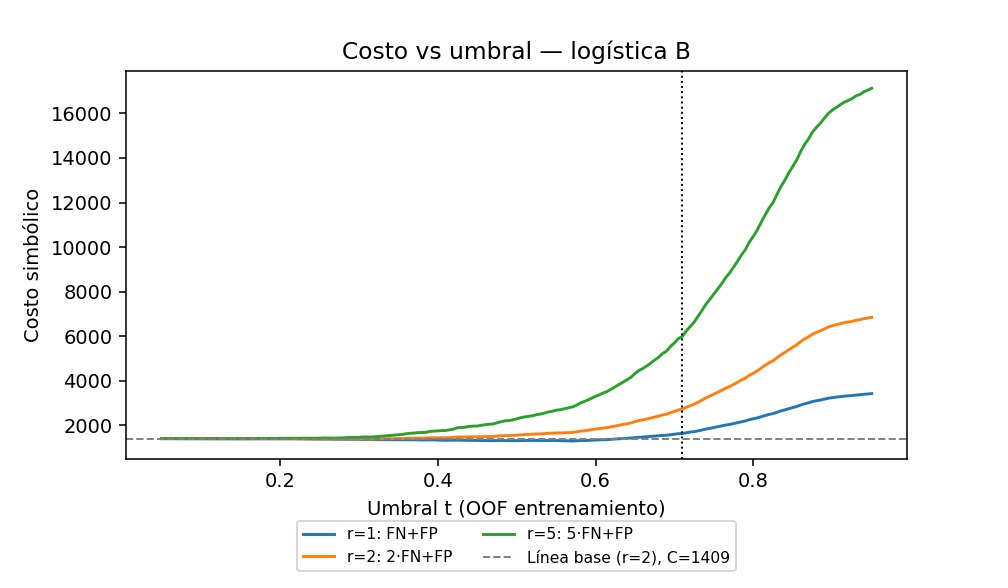

In [4]:
umb = json.loads((OUT_DIR / "umbrales_recomendados.json").read_text(encoding="utf-8"))
dest = pd.read_csv(OUT_DIR / "tabla_umbrales_destacados_oof.csv")
display(dest.round(3))
print(json.dumps(umb, indent=2, ensure_ascii=False))
display(Image(filename=str(OUT_DIR / "fig_costo_vs_umbral.png")))


## 4. Modelo final serializado

Pipeline completo ajustado en **todo el entrenamiento** (escenario B, sin balanceo). Mismo objeto usará Streamlit.


In [5]:
print("Archivo:", OUT_DIR / "pipeline_logistica_B.joblib")
pd.read_csv(OUT_DIR / "tabla_configuracion_definitiva.csv")


Archivo: C:\Users\agars\Documents\U\Sem 4\Materias\Machine Learning 1\Corte 2\Proyecto\codigo\salidas_tercera\pipeline_logistica_B.joblib


,modelo,escenario,variables,balanceo,semilla,particion,k_knn_referencia_cv
0,"LogisticRegression(C=1e6, max_iter=5000)",B. Principal (sin atraso ni clasif_sbs),"['edad', 'dias_lab', 'exp_sf', 'nivel_ahorro',...",ninguno,42,80/20 estratificada,151


## 5. Conjunto de prueba — solo lectura

- `tabla_test_cierre_segunda_entrega.csv` copia la evaluación de la 2.ª entrega.
- `tabla_test_verificacion_solo_lectura.csv` comprueba que, con el mismo split y semilla, el AUC coincide.
- `tabla_test_umbrales_solo_lectura.csv` aplica umbrales **ya elegidos en OOF** (reporte, no optimización).


In [6]:
display(pd.read_csv(OUT_DIR / "tabla_test_cierre_segunda_entrega.csv"))
display(pd.read_csv(OUT_DIR / "tabla_test_verificacion_solo_lectura.csv"))
display(pd.read_csv(OUT_DIR / "tabla_test_umbrales_solo_lectura.csv").round(3))


,Unnamed: 0,AUC,PR-AUC,Recall (mora=1),Precision (mora=1),F1 (mora=1),Recall (mora=0),Accuracy,VP,FN,FP,VN
0,Regresión logística,0.722,0.840,0.942,0.754,0.838,0.247,0.741,813,50,265,87
1,LDA,0.719,0.838,0.940,0.759,0.840,0.267,0.745,811,52,258,94
2,KNN,0.714,0.830,0.961,0.747,0.840,0.202,0.741,829,34,281,71
3,Naive Bayes,0.685,0.828,0.641,0.814,0.717,0.642,0.641,553,310,126,226
4,Línea base (siempre mora=1),0.500,0.710,1.000,0.710,0.831,0.000,0.710,863,0,352,0
5,Reg. logística (umbral Youden OOF),0.722,0.840,0.689,0.822,0.750,0.634,0.673,595,268,129,223
6,Reg. logística con peso de clases,0.720,0.840,0.683,0.819,0.745,0.631,0.667,589,274,130,222


,AUC_reentrenado_mismo_train_test,AUC_informe_segunda_entrega,uso
0,0.722,0.722,Verificación. No usar test para elegir modelo ...


,umbral,sensibilidad_TPR,especificidad_TNR,precision_mora1,FN,FP,VP,VN,escenario_umbral
0,0.500,0.942,0.247,0.754,50,265,813,87,convencion_0.5
1,0.710,0.689,0.634,0.822,268,129,595,223,youden_oof
2,0.570,0.905,0.349,0.773,82,229,781,123,costo_FN_1x_FP_oof
3,0.270,0.995,0.051,0.720,4,334,859,18,costo_FN_2x_FP_oof
4,0.135,1.000,0.000,0.710,0,352,863,0,costo_FN_5x_FP_oof


## 6. Copia de entregables para informe y presentación (Isabella)

Se replica la carpeta `entregables_para_informe` al ejecutar `python tercera_entrega_lib.py` desde terminal.


In [7]:
if INFORME_DIR.exists():
    run_entrega_final(INFORME_DIR)
    print("Listo:", INFORME_DIR.resolve())


C:\Users\agars\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\agars\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


C:\Users\agars\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\agars\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


C:\Users\agars\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\agars\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


C:\Users\agars\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


C:\Users\agars\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


C:\Users\agars\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\agars\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


C:\Users\agars\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


C:\Users\agars\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\agars\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


C:\Users\agars\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\agars\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


C:\Users\agars\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


Listo: C:\Users\agars\Documents\U\Sem 4\Materias\Machine Learning 1\Corte 2\Proyecto\documentacion\tercera_entrega\entregables_para_informe
